# AI Part 2: Perception (reading the paperwork)
**Provider Network Access and Cost Planner** · David Satizabal · CAI4505C Artificial Intelligence

The health plan's mailroom gets three kinds of scanned paperwork, and each one starts a different job:

| Document | What happens next |
|---|---|
| Claim form | Goes to claims, and becomes the cost data MI learns from |
| Referral | Starts a doctor search with the AI Part 1 planner |
| Provider enrollment form | Adds or updates a doctor in the directory |

This notebook teaches the agent to **see**. It loads the images, flattens them into numbers, trains a **softmax classifier** written from scratch, checks it with **confusion matrices**, and shows how **augmentation** makes it survive bad scans. The images are synthetic (seed 42): text is drawn as gray bars, so no real form or person appears.

**To run in Colab:** run the first cell. If the files are missing, it clones the class repo, or asks you to upload `AI_Part2_Perception.zip`.

In [1]:
# Find the project folder. If it's missing: clone the class repo, and if that fails, ask for the zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "AI_Part2_Perception"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content") / FOLDER,
              Path("/content/Artificial-Intelligence-Class") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_part2.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print(f"Project folder not found. Upload {FOLDER}.zip")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError(f"Put this notebook inside the {FOLDER} folder, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: AI_Part2_Perception


This cell finds the project files. In Colab it clones the class repo (finalProject branch), and if that fails it asks for a zip upload, so nothing crashes.

In [2]:
import pandas as pd, json
import gen_docs
gen_docs.main()          # rebuilds all 1,500 images from seed 42
labels = pd.read_csv("data/labels.csv")
display(labels.groupby(["set", "label"]).size().unstack())

label  claim_form  enrollment_form  referral
set                                         
messy         100              100       100
test           60               60        60
train         280              280       280
val            60               60        60


label,claim_form,enrollment_form,referral
set,,,
messy,100,100,100
test,60,60,60
train,280,280,280
val,60,60,60


**1,500 images, 64 x 64 pixels, grayscale.** For each document type:
- 280 for training, 60 for validation (to decide when to stop training), and 60 for the final test.
- 100 **messy scans** made with much more tilt, blur, noise and shadows. The model never trains on these. They show how it handles bad real-world scans.

{
 "Softmax, clean training": {
  "training_images": 840,
  "best_epoch": 73,
  "test": {
   "accuracy": 1.0,
   "macro_f1": 1.0,
   "per_class_f1": {
    "claim_form": 1.0,
    "referral": 1.0,
    "enrollment_form": 1.0
   },
   "confusion_matrix_rows_true_cols_pred": [
    [
     60,
     0,
     0
    ],
    [
     0,
     60,
     0
    ],
    [
     0,
     0,
     60
    ]
   ]
  },
  "messy": {
   "accuracy": 0.78,
   "macro_f1": 0.7854,
   "per_class_f1": {
    "claim_form": 0.7085,
    "referral": 0.8681,
    "enrollment_form": 0.7795
   },
   "confusion_matrix_rows_true_cols_pred": [
    [
     79,
     2,
     19
    ],
    [
     21,
     79,
     0
    ],
    [
     23,
     1,
     76
    ]
   ]
  }
 },
 "Softmax + augmentation": {
  "training_images": 2520,
  "best_epoch": 71,
  "test": {
   "accuracy": 1.0,
   "macro_f1": 1.0,
   "per_class_f1": {
    "claim_form": 1.0,
    "referral": 1.0,
    "enrollment_form": 1.0
   },
   "confusion_matrix_rows_true_cols_pred": [
 

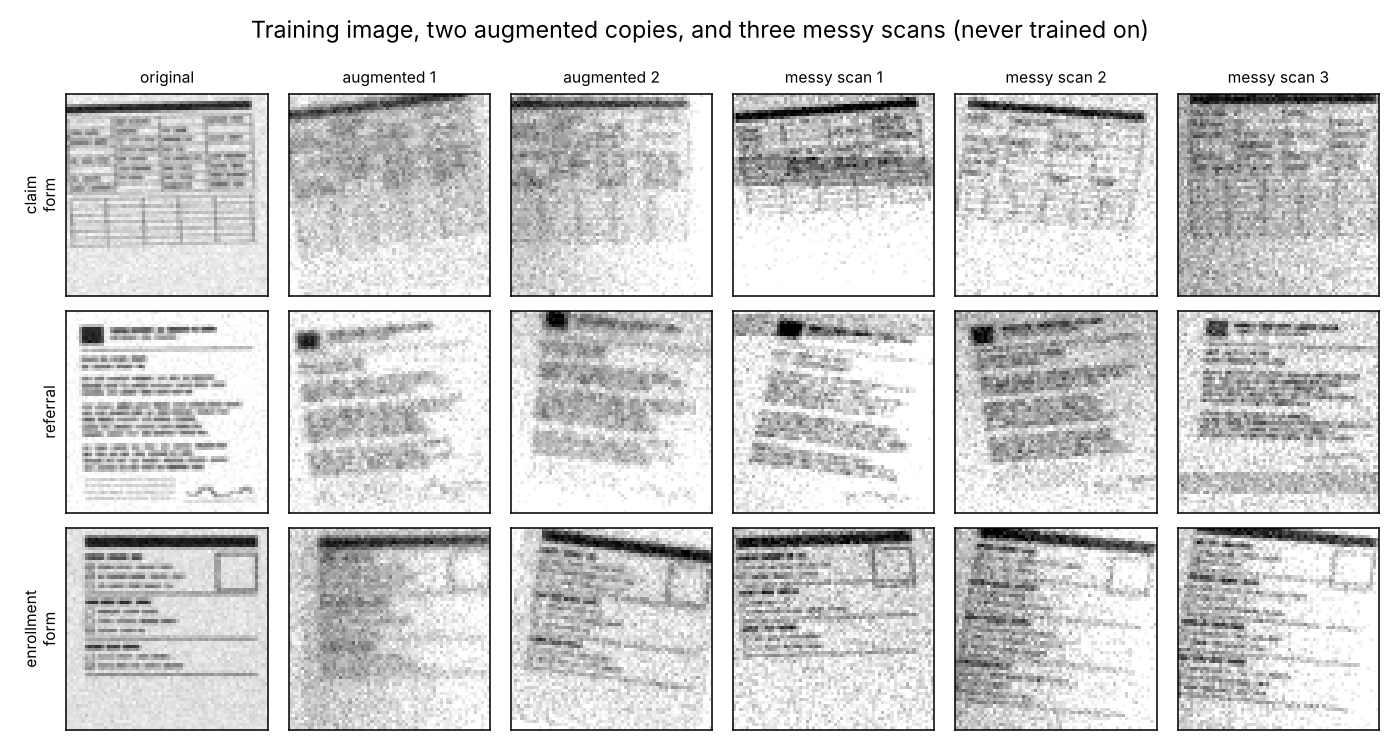

In [3]:
import run_part2
run_part2.main()
from IPython.display import Image
Image("outputs/augmented_samples.png")

**Augmentation** means making extra training copies that are tilted, shifted, blurred, noisy, or unevenly lit. It's like practicing reading bad handwriting before the test. Each training image gets 2 messy copies, so training grows from 840 to 2,520 images.

The test set and the messy scans are **never** augmented or trained on. They stay untouched so the scores are honest.

,model,training images,clean test accuracy,messy scan accuracy,messy macro F1
0,"Softmax, clean training",840,1.0,0.7800,0.7854
1,Softmax + augmentation,2520,1.0,0.9967,0.9967


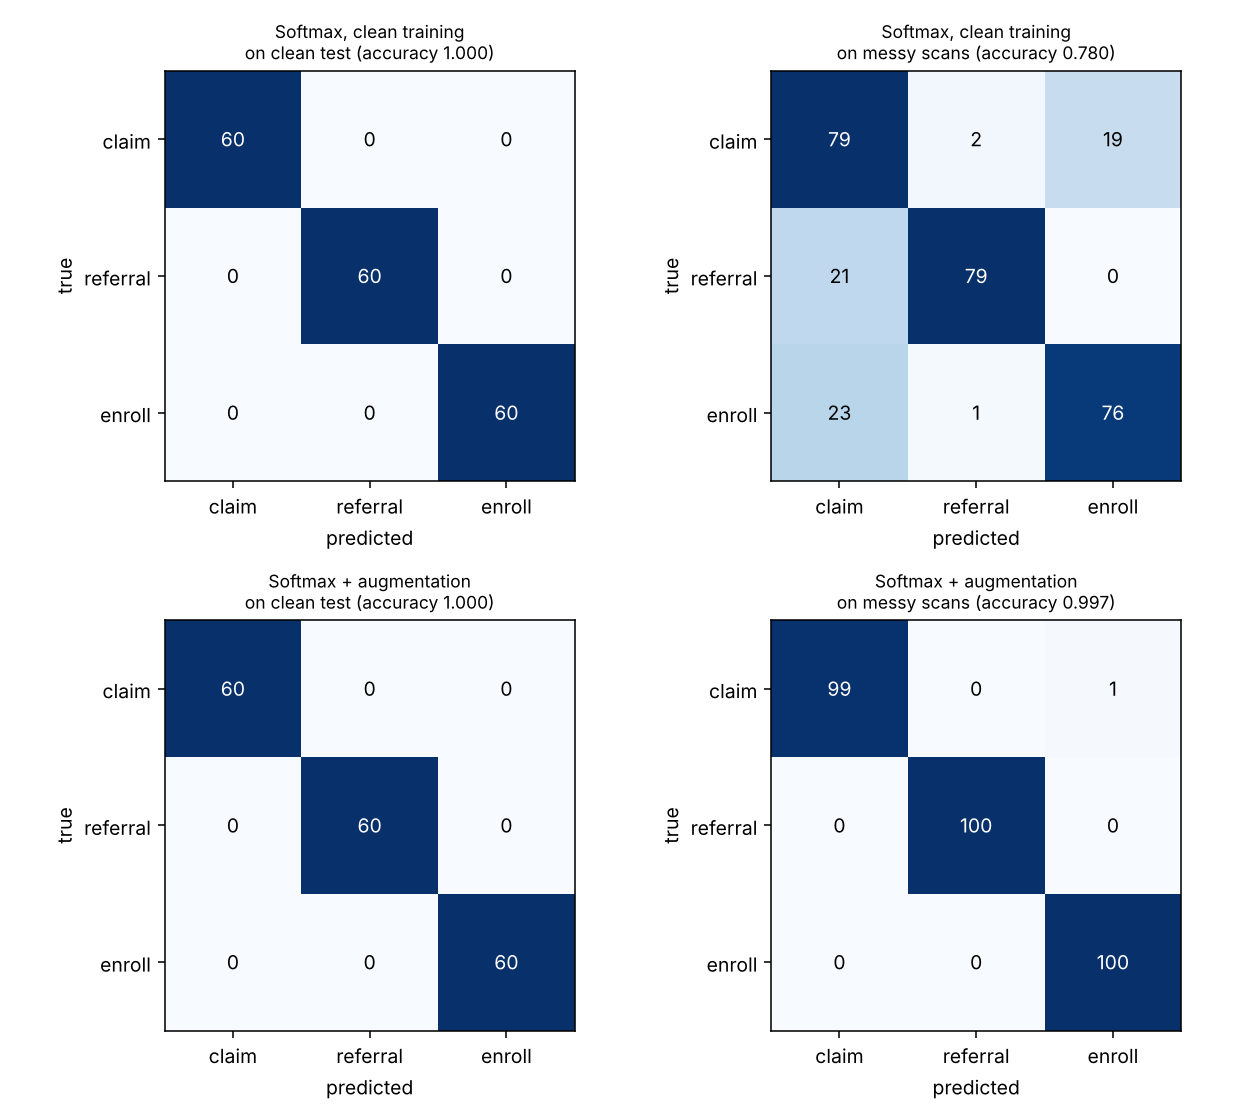

In [4]:
m = json.load(open("outputs/metrics.json"))
rows = [{"model": k, "training images": v["training_images"], "clean test accuracy": v["test"]["accuracy"],
         "messy scan accuracy": v["messy"]["accuracy"], "messy macro F1": v["messy"]["macro_f1"]} for k, v in m["models"].items()]
display(pd.DataFrame(rows))
Image("outputs/confusion_matrices.png")

**How the softmax classifier works:**
1. **Flatten:** each image becomes one row of 4,096 numbers (64 x 64 pixels), with ink = high and paper = low.
2. **Score:** each document type gets a score, which is a weighted sum of all 4,096 pixels plus a bias.
3. **Softmax** turns the three scores into percentages that add up to 100%.
4. **Train:** gradient descent nudges the weights to raise the percentage on the right answer. Training stops early when the validation loss stops improving (around epoch 71 to 73).

**Results:**
- Both models get **100% on the clean test**. The three layouts are very different, so clean scans are easy. That's a limitation of synthetic data worth saying out loud.
- On **messy scans**, the model trained only on clean images drops to **78%**. It mixed up all three types, mostly calling things claim forms.
- **With augmentation, messy-scan accuracy is 99.7%:** 299 of 300 correct, and the one miss is a claim form read as an enrollment form.

The confusion matrix is the mix-up chart. Each row is the true type, each column is what the model guessed, and everything off the diagonal is a mistake.

**Read the 99.7% with care.** The augmentation copies use the same kinds of damage (tilt up to 10 degrees, blur, noise, uneven light) as the messy-scan generator. So the model practiced on almost exactly the kind of mess it was tested on. Real scanners make mistakes we didn't simulate (folds, stamps, handwriting, faxes), so expect a lower number on real documents.

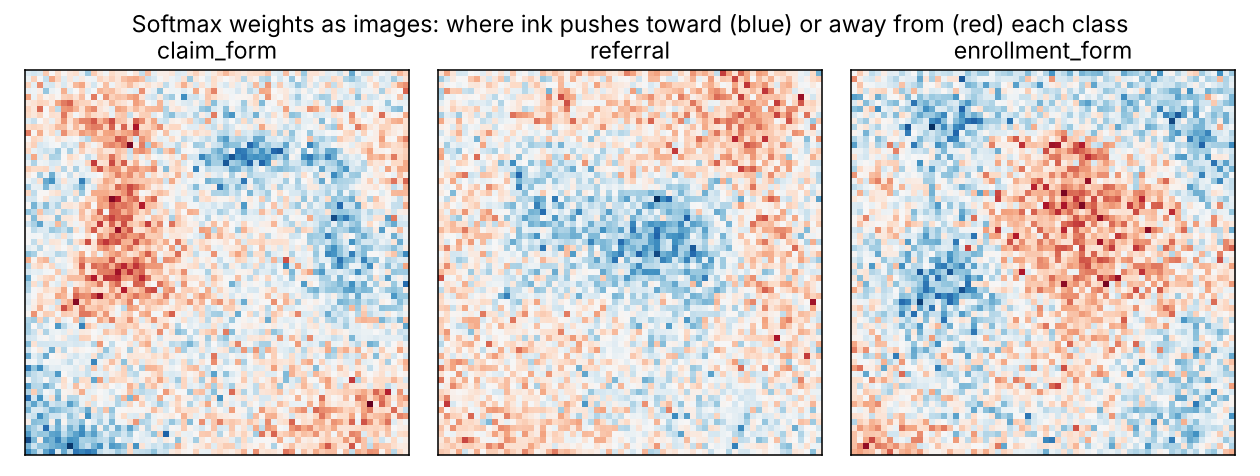

In [5]:
Image("outputs/weight_images.png")

**What the model looks at.** A softmax model has one weight per pixel per class, so each class's weights can be drawn as an image. Blue areas are where ink pushes toward that class, and red areas push away:
- **Enrollment form:** blue in the top-right (the ID photo box) and down the left side (the checkbox column).
- **Referral:** blue in the middle (paragraphs of text).
- **Claim form:** blue across the top and in the lower-left area (the grid of boxes and the line-item table).

It's matching **where** ink usually sits. That's also its weakness: a tilted or shifted scan moves the ink, which is why augmentation helps so much. A **CNN** solves this more directly by sliding small pattern detectors across the whole image, so a checkbox counts as a checkbox wherever it lands. The CNN is built in MI Part 3 on these same images.

,threshold,auto_routed_share,accuracy_of_auto_routed,sent_to_human,wrong_auto_routes
0,0.0,1.0000,0.9967,0,1
1,0.5,1.0000,0.9967,0,1
2,0.6,1.0000,0.9967,0,1
3,0.7,0.9933,1.0000,2,0
4,0.8,0.9900,1.0000,3,0
5,0.9,0.9833,1.0000,5,0


,file,true,predicted,confidence,next_step
0,enrollment_form_0409.png,enrollment_form,enrollment_form,1.000,add or update the provider directory
1,referral_0404.png,referral,referral,1.000,start a provider search (AI Part 1 planner)
2,enrollment_form_0466.png,enrollment_form,enrollment_form,1.000,add or update the provider directory
3,referral_0409.png,referral,referral,1.000,start a provider search (AI Part 1 planner)
4,enrollment_form_0450.png,enrollment_form,enrollment_form,1.000,add or update the provider directory
5,claim_form_0429.png,claim_form,claim_form,0.992,send to claims (feeds MI cost data)
6,claim_form_0474.png,claim_form,claim_form,1.000,send to claims (feeds MI cost data)
7,enrollment_form_0415.png,enrollment_form,enrollment_form,1.000,add or update the provider directory


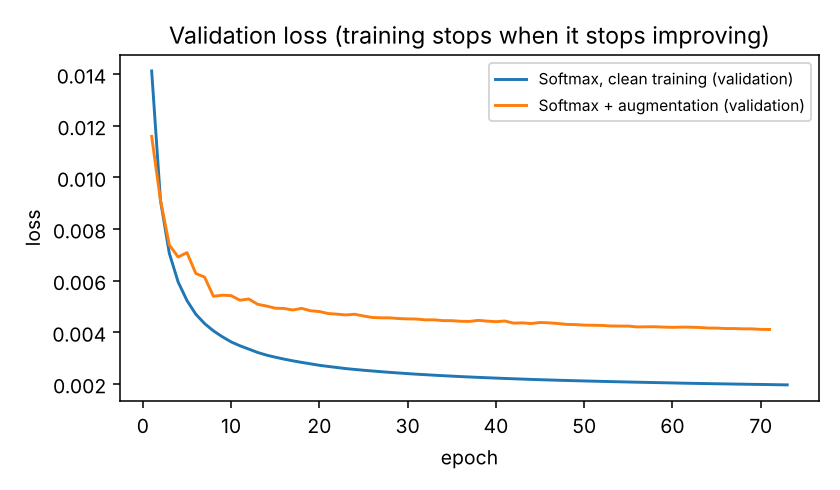

In [6]:
display(pd.DataFrame(m["routing_messy"]))
display(pd.DataFrame(m["routing_examples"]))
Image("outputs/training_curves.png")

**Routing (the agent part).** The classifier doesn't just label a document. It decides where the document goes. If the model is at least **70% confident**, the document goes straight to the next step. If it's less sure, a person reviews it.

On the 300 messy scans at the 70% line:
- 298 documents (99.3%) were routed automatically, with **zero wrong routes**.
- **2 went to a person.**
- With no threshold at all, 1 document would have been sent to the wrong team.

The 70% line was picked by looking at these same messy scans. A fair version would pick the line on separate validation scans and then test it once. That's the trade a real mailroom makes: a little human work in exchange for no misrouted claims.

**Summary.** A from-scratch softmax classifier reads all three document types perfectly on clean scans. Augmentation lifts messy-scan accuracy from 78% to 99.7%, and a 70% confidence threshold routes 99.3% of documents automatically with no errors.